# PCR vs PLS regression — *Communities and Crime* data

**Goal of the project.** Explain, for a non-expert reader, what Partial Least Squares (PLS) regression does and how it differs from
Principal Components Regression (PCR), using one real data set with many correlated predictors.

**The one-sentence answer we will illustrate.** Both methods replace the 100 original predictors by a few *components*
(linear combinations of the predictors) and regress the response on them. **PCR builds its components by looking only at $X$**
(directions of maximum variance), **PLS builds them by looking at $X$ *and* $y$** (directions of maximum covariance with the response).

**Code conventions.** The code follows the course notebooks (Chapter 1: PCA by eigen-decomposition of the correlation matrix;
Chapter 2: standardized $X$, centered $Y$, ridge and PCR written with the SVD of $X$) and the PLS algorithm of the slides by
G. Sanchez. scikit-learn is only used to *check* that our hand-written code gives the right numbers.

### Roadmap

| Part | Sections | What it does |
|---|---|---|
| **I. Data** | 1–4 | Load and clean the data; show that the predictors are strongly correlated (why PCR/PLS make sense here) |
| **II. The two methods, step by step** | 5–8 | Standardize; PCR with the SVD (course formulas); PLS with the slides' algorithm; compare what each one maximises |
| **III. Honest comparison of predictions** | 9–12 | Explain the cross-validation by **groups of states**; choose the number of components; measure the error on states never seen |
| **IV. When and why they differ** | 13–14 | Effect of the sample size; interpretation of components and coefficients |
| **V. Robustness** | 15–16 | Without the race variables; 20 different splits of the states |
| **VI. Conclusion** | 17–18 | Summary table, take-aways and limits |

---
# Part I — Data

## 1. Libraries and settings

Same libraries as in the course notebooks. Two global choices:

- `K_MAX = 40`: we try PCR and PLS with $k = 1, 2, \dots, 40$ components (beyond 40 nothing changes on this data set).
- `LAMBDAS`: the grid of penalties for the ridge regression, used as a *benchmark* (ridge is the other "shrinkage" method of Chapter 2).

In [ ]:
import re
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from numpy.linalg import eig, inv, svd

from sklearn.model_selection import GroupKFold, GroupShuffleSplit
from sklearn.cross_decomposition import PLSRegression   # only used to CHECK our own PLS code
from sklearn.decomposition import PCA                    # only used to CHECK our own PCR code
from sklearn.linear_model import LinearRegression        # only used to CHECK our own PCR code

warnings.filterwarnings("ignore")
plt.rcParams["figure.figsize"] = [10, 5]
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25})

# Colours used in every figure
C_PCR, C_PLS, C_RIDGE, C_OLS, C_MEAN = "#1f77b4", "#e07b00", "#2a9d5c", "#8c564b", "#888888"

SEED = 0
K_MAX = 40                            # numbers of components tried: 1, ..., 40
LAMBDAS = np.logspace(-2, 5, 60)      # ridge penalties tried (benchmark)
N_FOLDS = 5                           # 5 folds of STATES (see Section 9)

## 2. Loading the data

**Source.** UCI Machine Learning Repository, *Communities and Crime* (Redmond & Baveja, 2002), licence CC BY 4.0.
It combines the 1990 US Census, the 1990 LEMAS police survey and the 1995 FBI crime statistics.

- **1 994 communities** (cities/towns) in **46 states**.
- **128 columns**: 5 identifiers, 122 socio-economic predictors, and the response `ViolentCrimesPerPop`
  (violent crimes per 100 000 inhabitants).
- Every numeric variable has already been **normalized to [0, 1]** by the authors. So a value of 0.5 means "in the middle of the range of
  that variable", not "50 %".
- Missing values are coded `?`.

The two files `communities.data` (the values) and `communities.names` (the description, from which we read the column names)
must be in the same folder as this notebook.

In [ ]:
DATA_FILE = Path("/content/communities.data")
NAMES_FILE = Path("/content/communities.names")
if not (DATA_FILE.exists() and NAMES_FILE.exists()):
    raise FileNotFoundError("Put communities.data and communities.names in the same folder as this notebook.")

# Column names: the .names file contains one line '@attribute <name> <type>' per column
names = [m.group(1) for line in NAMES_FILE.read_text(errors="ignore").splitlines()
         if (m := re.match(r"@attribute\s+(\S+)", line))]

df = pd.read_csv(DATA_FILE, header=None, na_values="?")
df.columns = names

print("Shape of the data:", df.shape)
df.head()

Shape of the data: (1994, 128)


,state,county,community,communityname,fold,population,householdsize,racepctblack,racePctWhite,racePctAsian,...,LandArea,PopDens,PctUsePubTrans,PolicCars,PolicOperBudg,LemasPctPolicOnPatr,LemasGangUnitDeploy,LemasPctOfficDrugUn,PolicBudgPerPop,ViolentCrimesPerPop
0,8,NaN,NaN,Lakewoodcity,1,0.19,0.33,0.02,0.90,0.12,...,0.12,0.26,0.20,0.06,0.04,0.9,0.5,0.32,0.14,0.20
1,53,NaN,NaN,Tukwilacity,1,0.00,0.16,0.12,0.74,0.45,...,0.02,0.12,0.45,NaN,NaN,NaN,NaN,0.00,NaN,0.67
2,24,NaN,NaN,Aberdeentown,1,0.00,0.42,0.49,0.56,0.17,...,0.01,0.21,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.43
3,34,5.0,81440.0,Willingborotownship,1,0.04,0.77,1.00,0.08,0.12,...,0.02,0.39,0.28,NaN,NaN,NaN,NaN,0.00,NaN,0.12
4,42,95.0,6096.0,Bethlehemtownship,1,0.01,0.55,0.02,0.95,0.09,...,0.04,0.09,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.03


## 3. Cleaning

Three decisions, each explained:

1. **Drop the 5 identifiers** (`state`, `county`, `community`, `communityname`, `fold`): they are not predictors.
   We keep `state` aside in a vector `groups`: it will be used to split the data **by state** (Section 9).
2. **Drop the 22 police variables (LEMAS)**: they are missing for 1 675 of the 1 994 communities (84 %).
   Keeping them would force us to throw away 84 % of the rows.
3. **One remaining missing value** (`OtherPerCap`, one community). It is replaced by the median of the variable.
   In Parts III–V this is done *inside each training sample* (the median is computed without looking at the test data).

We end up with **1 994 communities × 100 predictors**.

In [ ]:
ID_COLS = ["state", "county", "community", "communityname", "fold"]
TARGET = "ViolentCrimesPerPop"

groups = df["state"].to_numpy()                 # state of each community (used for the grouped cross-validation)
Y = df[TARGET]
X_all = df.drop(columns=ID_COLS + [TARGET])

share_missing = X_all.isna().mean()
lemas_cols = share_missing[share_missing > 0.5].index.tolist()
X = X_all.drop(columns=lemas_cols)
FEATURES = X.columns.tolist()

print(f"Police (LEMAS) variables dropped: {len(lemas_cols)}")
print(f"Remaining missing values: {int(X.isna().sum().sum())} (in {X.columns[X.isna().any()].tolist()})")
print(f"Final data: n = {X.shape[0]} communities, p = {X.shape[1]} predictors, {len(np.unique(groups))} states")

Police (LEMAS) variables dropped: 22
Remaining missing values: 1 (in ['OtherPerCap'])
Final data: n = 1994 communities, p = 100 predictors, 46 states


count    1994.000
mean        0.238
std         0.233
min         0.000
25%         0.070
50%         0.150
75%         0.330
max         1.000
Name: ViolentCrimesPerPop, dtype: float64


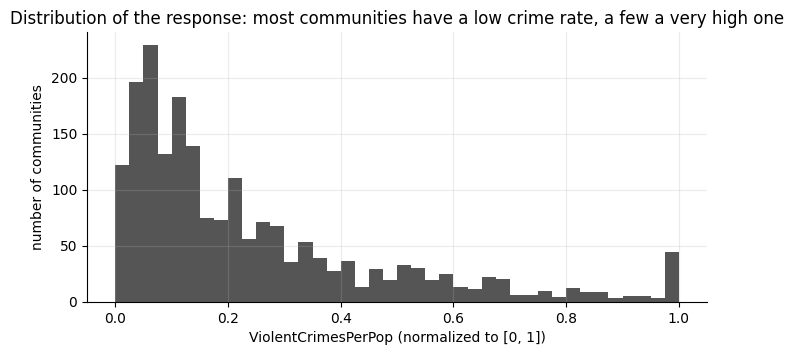

In [ ]:
# The response variable
print(Y.describe().round(3))

plt.figure(figsize=(8, 3.5))
plt.hist(Y, bins=40, color="#555")
plt.xlabel("ViolentCrimesPerPop (normalized to [0, 1])"); plt.ylabel("number of communities")
plt.title("Distribution of the response: most communities have a low crime rate, a few a very high one")
plt.show()